

To get started, we'll first install the OpenAI Whisper Python package using `pip`.

In [ ]:
%%capture
! pip install git+https://github.com/openai/whisper.git


In [ ]:
# make sure the GPU backend is enabled
! nvidia-smi -L

In [ ]:
! pip list  | grep "whisper"

In [ ]:
import whisper

import torch
torch.__version__

Whisper has a variety of models of varying sizes. The large model will be more accurate but will also be more resource intensive.

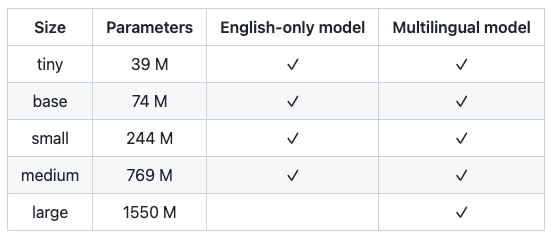

The base model will be sufficient for our needs. Let's load the base model like so:

In [ ]:
model = whisper.load_model('base')

In [ ]:
# download an audio file of a speech from Jerome Powell
! gdown 1t3YiYbzWyQkWhNQZ0uq2Fcxe56i9FiMU

Now you can play this hour-long audio clip for a preview by running the code below:

In [ ]:
from IPython.display import Audio

Audio("powell_speech.m4a", autoplay=True)

We want to ignore any additional sound and speech after Jerome Powell speaks. So we'll use `ffmpeg` to do this. The command will start the audio file at the 375 second mark where he starts with good afternoon, continue for 2715 seconds, and chop off the rest of the audio. The result will be saved in a new file called *fed_meeting_trimmed.mp4*.

In [ ]:
# create a 40-min trimmed version
!ffmpeg -ss 378 -i powell_speech.m4a -t 2715 fed_meeting_trimmed.mp4

Now you can play the trimmed audio to preview its content before starting transcription:

In [ ]:
Audio("fed_meeting_trimmed.mp4", autoplay=True)

The following code uses Whisper's base model to transcribe the trimmed audio. Processing will take approximately 2 minutes and 30 seconds on Colab with a T4 GPU:

In [ ]:
import datetime

# save a timestamp before transcription
t1 = datetime.datetime.now()
print(f"started at {t1}")

# do the transcription
output = model.transcribe("fed_meeting_trimmed.mp4")

# show time elapsed after transcription is complete.
t2 = datetime.datetime.now()
print(f"ended at {t2}")
print(f"time elapsed: {t2 - t1}")

What returns is a dictionary of the following entries:

In [ ]:
for key in output:
  print(key)

In [ ]:
output['text']

In [ ]:
for segment in output['segments']:
    print(segment)
    second = int(segment['start'])
    second = second - (second % 5)
    print(second)